<a href="https://colab.research.google.com/github/hariaksh-101/tess-exoplanet-hunt/blob/main/01_recovering_pi_mensae_c_with_TESS.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [1]:
!pip install lightkurve


In [2]:
import lightkurve as lk
print(lk.__version__)

search = lk.search_lightcurve("Pi Mensae", mission="TESS", author="SPOC")
print(search)

/usr/local/lib/python3.13/dist-packages/lightkurve/prf/__init__.py:7: UserWarning: Warning: the tpfmodel submodule is not available without oktopus installed, which requires a current version of autograd. See #1452 for details.
  warnings.warn(


2.6.0
SearchResult containing 42 data products.

 #     mission     year author exptime target_name distance
                                  s                 arcsec 
--- -------------- ---- ------ ------- ----------- --------
  0 TESS Sector 01 2018   SPOC     120   261136679      0.0
  1 TESS Sector 04 2018   SPOC     120   261136679      0.0
  2 TESS Sector 08 2019   SPOC     120   261136679      0.0
  3 TESS Sector 11 2019   SPOC     120   261136679      0.0
  4 TESS Sector 12 2019   SPOC     120   261136679      0.0
  5 TESS Sector 13 2019   SPOC     120   261136679      0.0
  6 TESS Sector 27 2020   SPOC      20   261136679      0.0
  7 TESS Sector 28 2020   SPOC      20   261136679      0.0
  8 TESS Sector 31 2020   SPOC      20   261136679      0.0
  9 TESS Sector 27 2020   SPOC     120   261136679      0.0
 10 TESS Sector 28 2020   SPOC     120   261136679      0.0
 11 TESS Sector 31 2020   SPOC     120   261136679      0.0
 12 TESS Sector 34 2021   SPOC      20   261136679 

<Axes: xlabel='Time - 2457000 [BTJD days]', ylabel='Normalized Flux'>

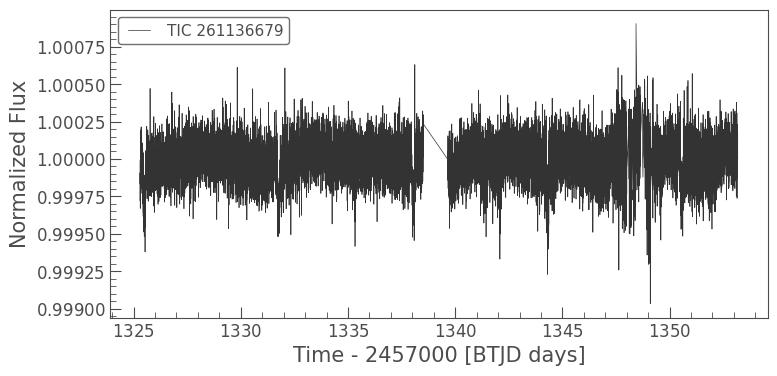

In [3]:
lc = search[0].download()
lc = lc.remove_nans().normalize()
lc.plot()

<Axes: xlabel='Time - 2457000 [BTJD days]', ylabel='Normalized Flux'>

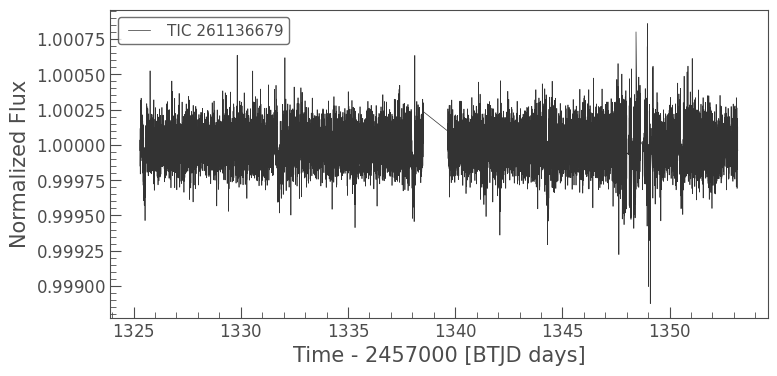

In [4]:
flat = lc.flatten(window_length=901)
flat.plot()

Period (days): 6.26599999999942 d
Dip depth: 0.0002459997108286941


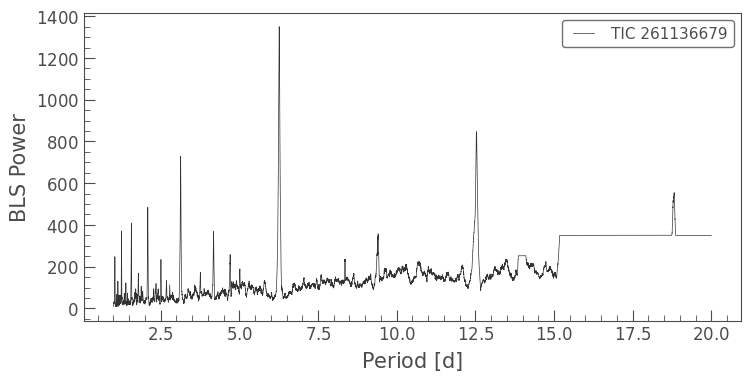

In [5]:
import numpy as np
pg = flat.to_periodogram(method="bls",
                         period=np.arange(1, 20, 0.001),
                         duration=[0.05, 0.08, 0.1, 0.15])
pg.plot()
print("Period (days):", pg.period_at_max_power)
print("Dip depth:", pg.depth_at_max_power)

<Axes: xlabel='Phase [JD]', ylabel='Normalized Flux'>

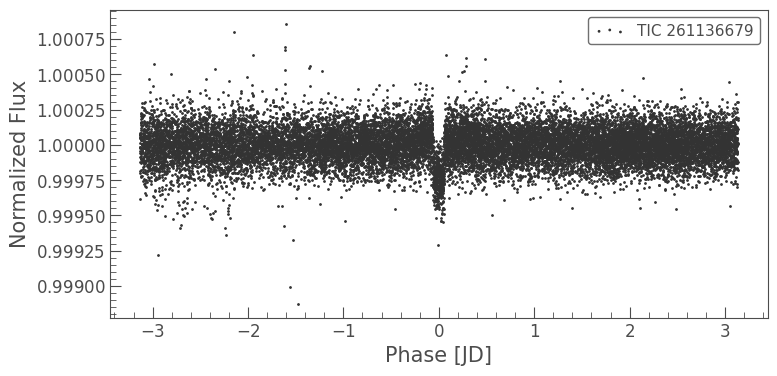

In [6]:
period = pg.period_at_max_power
t0 = pg.transit_time_at_max_power
flat.fold(period=period, epoch_time=t0).scatter()